# Experiment 4 — Cross-Validated Baseline & Residual Diagnosis

Builds on the experiment-3.2 direct-regression model (LightGBM on domain + time +
per-series mean; single-split held-out **WAPE 16.53**). Before adding any complexity:

1. **Step 1 — rolling-origin CV** (3 expanding-window folds, each test = 336h) with
   `series_mean` recomputed from each fold's *train* portion only. A trustworthy,
   leakage-free estimate that shows how stable 16.5 really is.
2. **Step 2 — residual diagnosis** — where the error lives (by hour, series, feature
   regime, bias), to decide whether lagged/lead domain features and per-series terms are
   worth adding (steps 3-6) or whether we are near the noise floor.

Standalone notebook — no PyTorch, no autoregression. Runs top to bottom on Kaggle.

---
## 1. Config

In [1]:
from pathlib import Path

DATA_DIR     = Path("/kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data")
BASELINE_DIR = Path("/kaggle/input/datasets/xitij27/baseline-code/baseline")
OUTPUT_DIR   = Path("/kaggle/working")

TRAIN_PATH     = DATA_DIR / "train.csv"
VAL_INPUT_PATH = DATA_DIR / "validation_input.csv"
VAL_INDEX_PATH = DATA_DIR / "forecast_index_validation.csv"

SEED         = 42
EVAL_HORIZON = 336          # 14-day forecast block
N_FOLDS      = 3            # rolling-origin CV folds

DOMAIN_FEAT_COLS = [
    'workload_intensity', 'demand_forecast', 'upstream_quality_forecast',
    'promotion_intensity', 'shock_risk', 'maintenance_known',
    'unit_reliability_forecast', 'queue_pressure_forecast',
    'network_pressure_forecast', 'event_load_forecast',
    'service_irregularity_risk_forecast',
]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for p in [TRAIN_PATH, VAL_INPUT_PATH, VAL_INDEX_PATH, BASELINE_DIR / "baselines.py"]:
    print(f"{'OK' if p.exists() else 'MISSING':8s} {p}")

OK       /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data/train.csv
OK       /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data/validation_input.csv
OK       /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data/forecast_index_validation.csv
OK       /kaggle/input/datasets/xitij27/baseline-code/baseline/baselines.py


---
## 2. Imports & Data

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import lightgbm as lgb

if str(BASELINE_DIR) not in sys.path:
    sys.path.insert(0, str(BASELINE_DIR))
from baselines import make_all_baselines

np.random.seed(SEED)

train_df     = pd.read_csv(TRAIN_PATH,     parse_dates=["timestamp"])
val_input_df = pd.read_csv(VAL_INPUT_PATH, parse_dates=["timestamp"])
val_index_df = pd.read_csv(VAL_INDEX_PATH, parse_dates=["timestamp"])
N_SERIES = train_df["series_id"].nunique()

print(f"train_df {train_df.shape}   val_input_df {val_input_df.shape}   series {N_SERIES}")

train_df (414720, 25)   val_input_df (32256, 24)   series 96


---
## 3. Metrics, Features, and Model

In [3]:
def wape(y_true, y_pred, eps=1e-8):
    return np.sum(np.abs(y_true - y_pred)) / (np.sum(np.abs(y_true)) + eps) * 100

TIME_COLS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos", "is_weekend"]

def add_time_features(df, time_col="timestamp"):
    df = df.copy()
    t = pd.to_datetime(df[time_col])
    df["hour_sin"]   = np.sin(2 * np.pi * t.dt.hour / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * t.dt.hour / 24)
    df["dow_sin"]    = np.sin(2 * np.pi * t.dt.dayofweek / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * t.dt.dayofweek / 7)
    df["doy_sin"]    = np.sin(2 * np.pi * t.dt.dayofyear / 365)
    df["doy_cos"]    = np.cos(2 * np.pi * t.dt.dayofyear / 365)
    df["is_weekend"] = (t.dt.dayofweek >= 5).astype(float)
    return df

def impute_domain_features(df, domain_cols):
    # forward-fill short gaps within each series, then zero-fill leading NaNs
    df = df.copy().sort_values(["series_id", "timestamp"])
    for col in domain_cols:
        if col in df.columns:
            df[col] = df.groupby("series_id")[col].transform(lambda x: x.ffill().fillna(0))
    return df

def make_lgbm():
    return lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=63,
                             subsample=0.8, colsample_bytree=0.8, min_child_samples=50,
                             reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbosity=-1)

GBM_FEATS = DOMAIN_FEAT_COLS + TIME_COLS + ["series_mean"]
LIN_FEATS = DOMAIN_FEAT_COLS + ["series_mean"]

---
## 4. Step 1 — Rolling-origin CV (leakage-free `series_mean`)

3 expanding-window folds; each test block = 336h. `series_mean` is recomputed from each
fold's **train** portion only, closing the ~8% peek in the single-split 16.53 estimate.
The `lightgbm` mean +/- std is the trustworthy baseline every later change is measured against.

In [4]:
base = add_time_features(impute_domain_features(train_df, DOMAIN_FEAT_COLS))

def fold_split(df, end_off, length=EVAL_HORIZON):
    tr, te = [], []
    for _, g in df.groupby("series_id", sort=False):
        g = g.sort_values("timestamp"); cut = len(g) - end_off
        tr.append(g.iloc[:cut]); te.append(g.iloc[cut:cut + length])
    tr, te = pd.concat(tr, ignore_index=True), pd.concat(te, ignore_index=True)
    sm = tr.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
    return tr.merge(sm, on="series_id"), te.merge(sm, on="series_id")

oof_list, res = [], {"seasonal": [], "linear": [], "lightgbm": []}
print(f"{'fold':>4}  {'tr_days':>7}  {'seasonal':>9}  {'linear':>7}  {'lightgbm':>9}")
print("-" * 46)
for k in range(N_FOLDS):
    end_off = (N_FOLDS - k) * EVAL_HORIZON
    tr, te  = fold_split(base, end_off)
    ytr, yte = tr["target"].to_numpy(float), te["target"].to_numpy(float)

    w_lin = wape(yte, np.maximum(LinearRegression().fit(tr[LIN_FEATS], ytr).predict(te[LIN_FEATS]), 0.0))
    gbm   = make_lgbm().fit(tr[GBM_FEATS], ytr)
    p_gbm = np.maximum(gbm.predict(te[GBM_FEATS]), 0.0)
    w_gbm = wape(yte, p_gbm)

    idx = te[["series_id", "timestamp"]]
    sm_pred = idx.merge(make_all_baselines(tr, idx)["seasonal_mean"],
                        on=["series_id", "timestamp"], how="left")["prediction"].to_numpy(float)
    w_sm = wape(yte, sm_pred)

    res["seasonal"].append(w_sm); res["linear"].append(w_lin); res["lightgbm"].append(w_gbm)
    oof_list.append(te.assign(pred_gbm=p_gbm, fold=k))
    print(f"{k:>4}  {len(tr)//N_SERIES//24:>7}  {w_sm:>9.3f}  {w_lin:>7.3f}  {w_gbm:>9.3f}")

cv_oof = pd.concat(oof_list, ignore_index=True)
print("-" * 46)
print(f"{'mean':>4}  {'':>7}  {np.mean(res['seasonal']):>9.3f}  {np.mean(res['linear']):>7.3f}  {np.mean(res['lightgbm']):>9.3f}")
print(f"{'std':>4}  {'':>7}  {np.std(res['seasonal']):>9.3f}  {np.std(res['linear']):>7.3f}  {np.std(res['lightgbm']):>9.3f}")
print(f"\nExp-3.2 model CV-WAPE = {np.mean(res['lightgbm']):.3f} +/- {np.std(res['lightgbm']):.3f}   (single-split was 16.53)")

fold  tr_days   seasonal   linear   lightgbm
----------------------------------------------
   0      138     30.168   17.416     16.282
   1      152     37.272   19.238     18.990
   2      166     31.404   18.089     16.546
----------------------------------------------
mean              32.948   18.247     17.273
 std               3.099    0.752      1.219

Exp-3.2 model CV-WAPE = 17.273 +/- 1.219   (single-split was 16.53)


---
## 5. Step 2 — Residual diagnosis

Out-of-fold errors broken down by hour-of-day, series, and `queue_pressure_forecast`
regime, plus a global bias check. Concentrated error or bias => structure left to capture
(steps 3-6). Flat and unbiased => near the noise floor; ship the 16.5 model.

Out-of-fold WAPE (all 3 folds, 96,768 rows): 17.174

WAPE by hour-of-day : min 14.06 (h20), max 25.61 (h1)
WAPE by series      : best 8.55, median 16.93, worst 27.99
  worst 5 series    : {'unit_073': 27.99, 'unit_058': 24.66, 'unit_022': 24.17, 'unit_066': 24.1, 'unit_056': 24.09}

WAPE by queue_pressure_forecast quintile:
qp_q
(-0.001, 2.016]    28.04
(2.016, 4.083]     19.91
(4.083, 5.96]      16.97
(5.96, 8.376]      15.00
(8.376, 24.752]    13.97

Mean bias (pred - actual): -0.306   vs target mean 10.55


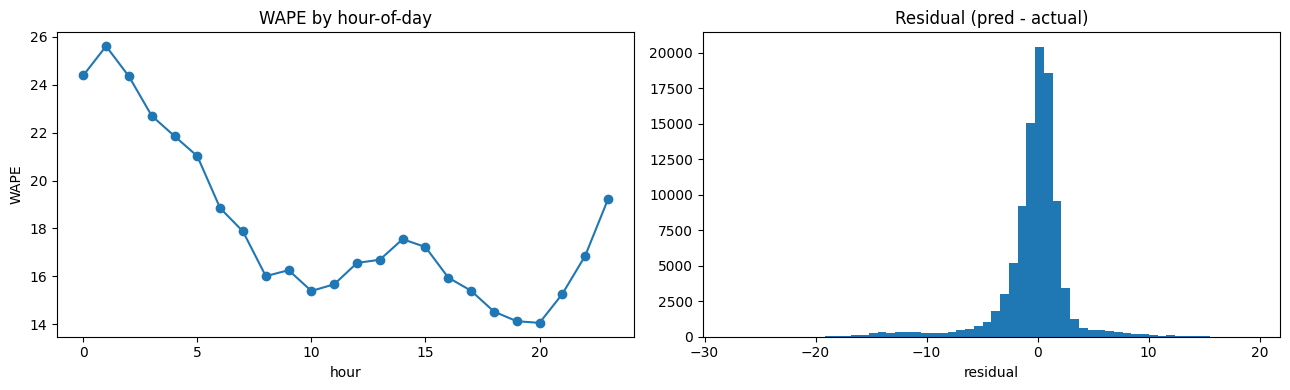

In [5]:
oof = cv_oof.copy()
oof["abs_err"] = (oof["target"] - oof["pred_gbm"]).abs()
oof["hour"]    = oof["timestamp"].dt.hour

overall = 100 * oof["abs_err"].sum() / oof["target"].sum()
print(f"Out-of-fold WAPE (all {N_FOLDS} folds, {len(oof):,} rows): {overall:.3f}\n")

def wape_by(key):
    g = oof.groupby(key, observed=True).agg(ae=("abs_err", "sum"), tot=("target", "sum"))
    return 100 * g["ae"] / g["tot"]

bh = wape_by("hour")
print(f"WAPE by hour-of-day : min {bh.min():.2f} (h{int(bh.idxmin())}), max {bh.max():.2f} (h{int(bh.idxmax())})")

bs = wape_by("series_id").sort_values(ascending=False)
print(f"WAPE by series      : best {bs.min():.2f}, median {bs.median():.2f}, worst {bs.max():.2f}")
print(f"  worst 5 series    : {bs.head(5).round(2).to_dict()}")

oof["qp_q"] = pd.qcut(oof["queue_pressure_forecast"], 5, duplicates="drop")
bq = wape_by("qp_q")
print("\nWAPE by queue_pressure_forecast quintile:")
print(bq.round(2).to_string())

bias = (oof["pred_gbm"] - oof["target"]).mean()
print(f"\nMean bias (pred - actual): {bias:+.3f}   vs target mean {oof['target'].mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bh.plot(ax=ax[0], marker="o"); ax[0].set_title("WAPE by hour-of-day"); ax[0].set_xlabel("hour"); ax[0].set_ylabel("WAPE")
ax[1].hist((oof["pred_gbm"] - oof["target"]).to_numpy(), bins=60); ax[1].set_title("Residual (pred - actual)"); ax[1].set_xlabel("residual")
plt.tight_layout(); plt.show()

---
## 6. Roadmap — steps 3-6 (gated on the diagnosis above)

- **If error concentrates in specific hours / `queue_pressure` regimes, or shows bias** ->
  structure remains:
  - **Step 3 — align objective with WAPE.** Test LightGBM `objective='mae'`, `'poisson'`,
    `'tweedie'` (target is non-negative/skewed); pick by CV-WAPE. Low effort.
  - **Step 4 — leakage-free temporal context.** Lags *and leads* of the domain features
    (e.g. `queue_pressure_forecast` at t-1 / t-24 / t+1) + rolling mean/std. All known across
    the horizon in `validation_input.csv`.
  - **Step 5 — per-series structure.** `series_id` as a LightGBM categorical and/or
    per-series feature scaling (within-r2 53% > pooled 47%).
  - **Step 6 — light tuning + linear/GBM ensemble.**
- **If error is flat and unbiased across every cut** -> near the noise floor; stop and ship.

Re-evaluate every change on the Step-1 CV (mean +/- std), never on a single split.

---
## 7. Step 3 + 5 — Objective × `series_id` categorical

The Step-2 diagnosis flagged two leverage points:

- **Per-series WAPE spread of 19 points** (8.5 → 28; worst series `unit_073` at 28.0). The
  global model is averaging over very different per-series relationships. Adding `series_id`
  as a native LightGBM categorical lets the model split on unit identity (Step 5).
- **WAPE inflates at low `queue_pressure` / low-y hours** (28 → 14 monotonic). Partly a
  WAPE-mechanism artifact, but also consistent with L2 under-fitting low-y rows. Switching
  the LightGBM objective to `mae` / `poisson` / `tweedie` aligns training with the metric
  (Step 3).

This section evaluates the **4 × 2 grid** (objective × with/without `series_id`) on the same
3-fold rolling-origin CV from §4, then refits the winner on all of `train.csv` and writes a
new `validation_predictions.csv`. Sanity check: the `L2 / no` cell should reproduce the §4
LightGBM CV-WAPE (~17.27).

In [6]:
# ── Step 3 + 5: objective × series_id categorical, on the §4 rolling CV ───────
# Stable series_id -> int code, shared across train and validation_input.
sid_to_code = {s: i for i, s in enumerate(sorted(train_df["series_id"].unique()))}
base["sid_code"] = base["series_id"].map(sid_to_code).astype("int32")

OBJECTIVES = {
    "L2":      {"objective": "regression"},
    "MAE":     {"objective": "regression_l1"},
    "Poisson": {"objective": "poisson"},
    "Tweedie": {"objective": "tweedie", "tweedie_variance_power": 1.5},
}
CAT_FEAT = ["sid_code"]

def make_lgbm_obj(obj_kw):
    return lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=63,
                             subsample=0.8, colsample_bytree=0.8, min_child_samples=50,
                             reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbosity=-1,
                             **obj_kw)

GRID = [(name, kw, use_cat)
        for name, kw in OBJECTIVES.items()
        for use_cat in (False, True)]

print(f"{'objective':>10}  {'series_id':>10}  {'fold0':>6}  {'fold1':>6}  {'fold2':>6}  {'mean':>6}  {'std':>5}")
print("-" * 62)
grid_results = []
for name, obj_kw, use_cat in GRID:
    feats  = GBM_FEATS + (CAT_FEAT if use_cat else [])
    fit_kw = {"categorical_feature": CAT_FEAT} if use_cat else {}
    fold_wapes = []
    for k in range(N_FOLDS):
        end_off = (N_FOLDS - k) * EVAL_HORIZON
        tr, te  = fold_split(base, end_off)
        ytr, yte = tr["target"].to_numpy(float), te["target"].to_numpy(float)
        m = make_lgbm_obj(obj_kw)
        m.fit(tr[feats], ytr, **fit_kw)
        p = np.maximum(m.predict(te[feats]), 0.0)
        fold_wapes.append(wape(yte, p))
    mean_w, std_w = float(np.mean(fold_wapes)), float(np.std(fold_wapes))
    grid_results.append({"obj": name, "cat": use_cat, "kw": obj_kw,
                         "feats": feats, "fit_kw": fit_kw,
                         "folds": fold_wapes, "mean": mean_w, "std": std_w})
    print(f"{name:>10}  {('yes' if use_cat else 'no'):>10}  "
          f"{fold_wapes[0]:>6.2f}  {fold_wapes[1]:>6.2f}  {fold_wapes[2]:>6.2f}  "
          f"{mean_w:>6.2f}  {std_w:>5.2f}")

baseline = next(r for r in grid_results if r["obj"] == "L2" and not r["cat"])
best     = min(grid_results, key=lambda r: r["mean"])
print(f"\nbaseline (L2, no series_id) : CV-WAPE = {baseline['mean']:.3f} +/- {baseline['std']:.3f}")
print(f"best  ({best['obj']}, series_id={'yes' if best['cat'] else 'no'}) : "
      f"CV-WAPE = {best['mean']:.3f} +/- {best['std']:.3f}   "
      f"(delta {best['mean'] - baseline['mean']:+.3f} vs baseline)")

 objective   series_id   fold0   fold1   fold2    mean    std
--------------------------------------------------------------
        L2          no   16.28   18.99   16.55   17.27   1.22
        L2         yes   15.35   18.71   15.86   16.64   1.48
       MAE          no   15.69   16.83   16.04   16.19   0.47
       MAE         yes   14.78   16.18   15.20   15.39   0.59
   Poisson          no   16.23   18.58   16.83   17.21   1.00
   Poisson         yes   15.18   17.73   15.79   16.23   1.09
   Tweedie          no   16.17   18.51   16.84   17.17   0.98
   Tweedie         yes   15.52   17.91   16.21   16.55   1.01

baseline (L2, no series_id) : CV-WAPE = 17.273 +/- 1.219
best  (MAE, series_id=yes) : CV-WAPE = 15.386 +/- 0.588   (delta -1.887 vs baseline)


In [7]:
# ── Refit grid winner on ALL train, predict validation_input.csv, save ────────
b = best

# Full training matrix: imputed domain + time + series_mean + (sid_code if cat)
tr_full = base.copy()
sm_full = tr_full.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
tr_full = tr_full.merge(sm_full, on="series_id")

final_model = make_lgbm_obj(b["kw"])
final_model.fit(tr_full[b["feats"]], tr_full["target"].to_numpy(float), **b["fit_kw"])

# Validation_input: same pipeline (imputation, time feats, series_mean, sid_code)
val = add_time_features(impute_domain_features(val_input_df, DOMAIN_FEAT_COLS))
val["sid_code"] = val["series_id"].map(sid_to_code).astype("int32")
val = val.merge(sm_full, on="series_id")
assert val["sid_code"].notna().all() and val["series_mean"].notna().all()

val["prediction"] = np.maximum(final_model.predict(val[b["feats"]]), 0.0)

submission = val_index_df.merge(val[["series_id", "timestamp", "prediction"]],
                                on=["series_id", "timestamp"], how="left")
assert submission["prediction"].notna().all(), "missing predictions for some index rows"
assert len(submission) == len(val_index_df), "row count mismatch vs forecast index"

VAL_PREDS_PATH = OUTPUT_DIR / "validation_predictions.csv"
submission[["series_id", "timestamp", "prediction"]].to_csv(VAL_PREDS_PATH, index=False)
print(f"Submission written : {len(submission):,} rows → {VAL_PREDS_PATH}")
print(f"Model              : {b['obj']} / series_id={'yes' if b['cat'] else 'no'}")
print(f"CV-WAPE            : {b['mean']:.3f} +/- {b['std']:.3f}   "
      f"(vs baseline L2/no: {baseline['mean']:.3f})")
print()
print(submission["prediction"].describe().round(3))

Submission written : 32,256 rows → /kaggle/working/validation_predictions.csv
Model              : MAE / series_id=yes
CV-WAPE            : 15.386 +/- 0.588   (vs baseline L2/no: 17.273)

count    32256.000
mean        10.539
std          5.145
min          1.309
25%          6.585
50%          9.771
75%         13.721
max         36.090
Name: prediction, dtype: float64


---
## 8. Step 4 — Leakage-free temporal context (lagged / lead / rolling domain features)

`validation_input.csv` provides the **full domain trajectory** across the 336h horizon, so
lags *and* leads of domain features are all known at prediction time (target lags remain
off-limits because val_input has no `target` column). The per-hour model so far ignores
temporal structure inside the covariates — `target[t]` may depend on `queue_pressure`
building up over the prior 24h, or on a known imminent spike.

On top of the §7 winner (**MAE objective + `series_id` categorical**) this section:

- adds **lags** at t−1, t−24 and **leads** at t+1, t+24 for the top 5 domain features (by
  OOS r²: `queue_pressure`, `network_pressure`, `workload_intensity`, `shock_risk`,
  `event_load`);
- adds **rolling mean + std** over 6h and 24h windows for the top 3
  (`queue_pressure`, `network_pressure`, `workload_intensity`);
- re-evaluates on the same 3-fold rolling-origin CV;
- re-runs the residual diagnosis on the new OOF predictions;
- refits and overwrites `validation_predictions.csv` **only if §8 beats §7**. The
  submission refit concatenates `train.csv` + `validation_input.csv` so val rows' lags
  reach back into training data and late-train rows' leads reach into val_input —
  consistent with the inference setup.

In [8]:
# ── Step 4: add leakage-free temporal context to the §7 winner ────────────────
TOP_DOM = [
    "queue_pressure_forecast",      # OOS r^2 ~47%
    "network_pressure_forecast",    # ~43%
    "workload_intensity",           # ~30%
    "shock_risk",                   # ~18%
    "event_load_forecast",          # ~14%
]
TOP3_ROLL = TOP_DOM[:3]
LAGS_DOM  = [1, 24]
LEADS_DOM = [1, 24]
ROLL_WINS = [6, 24]

def add_temporal_features(df, lag_cols, roll_cols, lags, leads, windows):
    df = df.copy().sort_values(["series_id", "timestamp"])
    new = []
    for col in lag_cols:
        gcol = df.groupby("series_id", sort=False)[col]
        for L in lags:
            c = f"{col}_lag{L}";  df[c] = gcol.shift(L);  new.append(c)
        for L in leads:
            c = f"{col}_lead{L}"; df[c] = gcol.shift(-L); new.append(c)
    for col in roll_cols:
        gcol = df.groupby("series_id", sort=False)[col]
        for w in windows:
            cm = f"{col}_rmean{w}"; cs = f"{col}_rstd{w}"
            df[cm] = gcol.transform(lambda x: x.rolling(w, min_periods=1).mean())
            df[cs] = gcol.transform(lambda x: x.rolling(w, min_periods=1).std())
            new += [cm, cs]
    return df, new

# CV uses train-only temporal feats; LightGBM handles NaN edges natively.
base_t, TEMP_COLS = add_temporal_features(base, TOP_DOM, TOP3_ROLL, LAGS_DOM, LEADS_DOM, ROLL_WINS)
GBM_FEATS_T = GBM_FEATS + TEMP_COLS + CAT_FEAT
print(f"Added {len(TEMP_COLS)} temporal features  →  {len(GBM_FEATS_T)} total features")

oof_t, fold_wapes = [], []
for k in range(N_FOLDS):
    end_off = (N_FOLDS - k) * EVAL_HORIZON
    tr, te  = fold_split(base_t, end_off)
    ytr, yte = tr["target"].to_numpy(float), te["target"].to_numpy(float)
    m = make_lgbm_obj({"objective": "regression_l1"})
    m.fit(tr[GBM_FEATS_T], ytr, categorical_feature=CAT_FEAT)
    p = np.maximum(m.predict(te[GBM_FEATS_T]), 0.0)
    fold_wapes.append(wape(yte, p))
    oof_t.append(te.assign(pred_t=p, fold=k))
    print(f"  fold {k}: WAPE = {fold_wapes[-1]:.3f}")

cv_oof_t = pd.concat(oof_t, ignore_index=True)
cv_t_mean, cv_t_std = float(np.mean(fold_wapes)), float(np.std(fold_wapes))
prev = best  # §7 winner (MAE + series_id, no temporal)

print(f"\n§8  MAE + series_id + temporal feats : CV-WAPE = {cv_t_mean:.3f} +/- {cv_t_std:.3f}")
print(f"§7  MAE + series_id (no temporal)    : CV-WAPE = {prev['mean']:.3f} +/- {prev['std']:.3f}")
print(f"delta                                : {cv_t_mean - prev['mean']:+.3f}")

Added 32 temporal features  →  52 total features
  fold 0: WAPE = 14.083
  fold 1: WAPE = 15.639
  fold 2: WAPE = 14.683

§8  MAE + series_id + temporal feats : CV-WAPE = 14.801 +/- 0.641
§7  MAE + series_id (no temporal)    : CV-WAPE = 15.386 +/- 0.588
delta                                : -0.584


In [9]:
# ── Residual re-diagnosis on the §8 OOF predictions ──────────────────────────
o = cv_oof_t.copy()
o["abs_err"] = (o["target"] - o["pred_t"]).abs()
o["hour"]    = o["timestamp"].dt.hour

overall = 100 * o["abs_err"].sum() / o["target"].sum()
print(f"§8 OOF WAPE (all {N_FOLDS} folds, {len(o):,} rows): {overall:.3f}\n")

def _wape_grp(key):
    g = o.groupby(key, observed=True).agg(ae=("abs_err", "sum"), tot=("target", "sum"))
    return 100 * g["ae"] / g["tot"]

bh = _wape_grp("hour")
print(f"WAPE by hour-of-day : min {bh.min():.2f} (h{int(bh.idxmin())}), max {bh.max():.2f} (h{int(bh.idxmax())})")

bs = _wape_grp("series_id").sort_values(ascending=False)
print(f"WAPE by series      : best {bs.min():.2f}, median {bs.median():.2f}, worst {bs.max():.2f}")
print(f"  worst 5 series    : {bs.head(5).round(2).to_dict()}")

o["qp_q"] = pd.qcut(o["queue_pressure_forecast"], 5, duplicates="drop")
bq = _wape_grp("qp_q")
print("\nWAPE by queue_pressure_forecast quintile:")
print(bq.round(2).to_string())

bias = (o["pred_t"] - o["target"]).mean()
print(f"\nMean bias (pred - actual): {bias:+.3f}   vs target mean {o['target'].mean():.2f}")

§8 OOF WAPE (all 3 folds, 96,768 rows): 14.746

WAPE by hour-of-day : min 11.69 (h19), max 21.39 (h1)
WAPE by series      : best 7.55, median 14.63, worst 25.96
  worst 5 series    : {'unit_073': 25.96, 'unit_058': 22.02, 'unit_066': 21.91, 'unit_056': 20.81, 'unit_039': 20.38}

WAPE by queue_pressure_forecast quintile:
qp_q
(-0.001, 2.016]    23.43
(2.016, 4.083]     17.55
(4.083, 5.96]      14.96
(5.96, 8.376]      13.04
(8.376, 24.752]    11.63

Mean bias (pred - actual): -0.483   vs target mean 10.55


In [10]:
# ── Refit §8 on ALL train + val_input (for cross-boundary temporal feats), save ─
# Only overwrite the submission if §8 actually beats §7.
if cv_t_mean < prev["mean"]:
    # Concat train + val_input so val rows' lags reach into train and train's leads
    # reach into val — consistent with how features look at real inference.
    val_stub = val_input_df.copy(); val_stub["target"] = np.nan
    combined = pd.concat([train_df, val_stub], ignore_index=True)
    combined = add_time_features(impute_domain_features(combined, DOMAIN_FEAT_COLS))
    combined["sid_code"] = combined["series_id"].map(sid_to_code).astype("int32")
    sm_full = train_df.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
    combined = combined.merge(sm_full, on="series_id")
    combined, _ = add_temporal_features(combined, TOP_DOM, TOP3_ROLL, LAGS_DOM, LEADS_DOM, ROLL_WINS)

    is_val   = combined["target"].isna()
    tr_full  = combined[~is_val]
    val_full = combined[is_val].copy()

    final = make_lgbm_obj({"objective": "regression_l1"})
    final.fit(tr_full[GBM_FEATS_T], tr_full["target"].to_numpy(float), categorical_feature=CAT_FEAT)
    val_full["prediction"] = np.maximum(final.predict(val_full[GBM_FEATS_T]), 0.0)

    submission = val_index_df.merge(val_full[["series_id", "timestamp", "prediction"]],
                                    on=["series_id", "timestamp"], how="left")
    assert submission["prediction"].notna().all(), "missing predictions for some index rows"
    assert len(submission) == len(val_index_df)

    submission[["series_id", "timestamp", "prediction"]].to_csv(VAL_PREDS_PATH, index=False)
    print(f"§8 beat §7 ({cv_t_mean:.3f} vs {prev['mean']:.3f}) — new submission written")
    print(f"   {len(submission):,} rows → {VAL_PREDS_PATH}")
    print()
    print(submission["prediction"].describe().round(3))
else:
    print(f"§8 did NOT beat §7 ({cv_t_mean:.3f} vs {prev['mean']:.3f}) — keeping the §7 submission.")

§8 beat §7 (14.801 vs 15.386) — new submission written
   32,256 rows → /kaggle/working/validation_predictions.csv

count    32256.000
mean        10.492
std          5.140
min          1.327
25%          6.536
50%          9.731
75%         13.703
max         35.673
Name: prediction, dtype: float64
